In [1]:
# Import Libraries

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
# Load Data

data_path = "data"

folders = sorted([
    os.path.join(data_path, folder)
    for folder in os.listdir(data_path)
    if folder.startswith("call-report-data-")
])

folders

['call-report-data-2022-06',
 'call-report-data-2022-09',
 'call-report-data-2022-12',
 'call-report-data-2023-03',
 'call-report-data-2023-06',
 'call-report-data-2023-09',
 'call-report-data-2023-12',
 'call-report-data-2024-03',
 'call-report-data-2024-06',
 'call-report-data-2024-09',
 'call-report-data-2024-12',
 'call-report-data-2025-03',
 'call-report-data-2025-06',
 'call-report-data-2025-09',
 'call-report-data-2025-12',
 'call-report-data-2026-03',
 'call-report-data-2026-06']

In [3]:
#Process Data 

def process_quarter(folder):
    # Load files
    fs220 = pd.read_csv(
        os.path.join(folder, "FS220.txt"),
        low_memory=False
    )

    fs220a = pd.read_csv(
        os.path.join(folder, "FS220A.txt"),
        low_memory=False
    )

    foicu = pd.read_csv(
        os.path.join(folder, "FOICU.txt"),
        low_memory=False
    )

    # Select financial columns
    fs220_selected = fs220[
        [
            "CU_NUMBER",
            "CYCLE_DATE",
            "ACCT_010",
            "ACCT_018",
            "ACCT_025A",
            "ACCT_025B",
            "ACCT_083"
        ]
    ].copy()

    fs220a_selected = fs220a[
        [
            "CU_NUMBER",
            "CYCLE_DATE",
            "Acct_661A",
            "Acct_997",
            "Acct_998"
        ]
    ].copy()

    # Merge financial files
    quarter = pd.merge(
        fs220_selected,
        fs220a_selected,
        on=["CU_NUMBER", "CYCLE_DATE"],
        how="left"
    )

    # Rename financial columns
    quarter = quarter.rename(columns={
        "CU_NUMBER": "Credit_Union_Number",
        "CYCLE_DATE": "Quarter",
        "ACCT_010": "Total_Assets",
        "ACCT_018": "Shares_Deposits",
        "ACCT_025A": "Number_of_Loans",
        "ACCT_025B": "Total_Loans",
        "ACCT_083": "Members",
        "Acct_661A": "Net_Income",
        "Acct_997": "Total_Net_Worth",
        "Acct_998": "Net_Worth_Ratio"
    })

    # Select credit union information
    foicu_selected = foicu[
        [
            "CU_NUMBER",
            "CYCLE_DATE",
            "CU_NAME",
            "CITY",
            "STATE",
            "CU_TYPE",
            "YEAR_OPENED",
            "Peer_Group"
        ]
    ].copy()

    # Merge credit union information
    quarter = pd.merge(
        quarter,
        foicu_selected,
        left_on=["Credit_Union_Number", "Quarter"],
        right_on=["CU_NUMBER", "CYCLE_DATE"],
        how="left"
    )

    quarter = quarter.drop(
        columns=["CU_NUMBER", "CYCLE_DATE"]
    )

    quarter = quarter.rename(columns={
        "CU_NAME": "Credit_Union_Name",
        "CITY": "City",
        "STATE": "State",
        "CU_TYPE": "Credit_Union_Type",
        "YEAR_OPENED": "Year_Opened"
    })

    # Convert date
    quarter["Quarter"] = pd.to_datetime(quarter["Quarter"])

    # Convert net worth ratio to percentage
    quarter["Net_Worth_Ratio"] = quarter["Net_Worth_Ratio"] / 100

    return quarter

In [4]:
#Combine Data

all_quarters = []

for folder in folders:
    quarter_data = process_quarter(folder)
    all_quarters.append(quarter_data)

combined_df = pd.concat(
    all_quarters,
    ignore_index=True
)

combined_df.shape

(78625, 16)

In [5]:
# Check all dates are loaded

print(
    "First qtr:",
    combined_df["Quarter"].min()
)

print(
    "Last qtr:",
    combined_df["Quarter"].max()
)

First qtr: 2022-06-30 00:00:00
Last qtr: 2026-06-30 00:00:00


In [6]:
combined_df["Quarter"].value_counts().sort_index()

Quarter
2022-06-30    4957
2022-09-30    4917
2022-12-31    4863
2023-03-31    4814
2023-06-30    4787
2023-09-30    4745
2023-12-31    4702
2024-03-31    4670
2024-06-30    4631
2024-09-30    4596
2024-12-31    4550
2025-03-31    4505
2025-06-30    4460
2025-09-30    4419
2025-12-31    4374
2026-03-31    4336
2026-06-30    4299
Name: count, dtype: int64

In [7]:
# Check data quality 

print("Shape:", combined_df.shape)

print("\nMissing values:")
print(combined_df.isnull().sum())

print("\nDuplicate rows:")
print(combined_df.duplicated().sum())

print("\nDuplicate credit union-quarter records:")
print(
    combined_df.duplicated(
        subset=["Credit_Union_Number", "Quarter"]
    ).sum()
)

Shape: (78625, 16)

Missing values:
Credit_Union_Number    0
Quarter                0
Total_Assets           0
Shares_Deposits        0
Number_of_Loans        0
Total_Loans            0
Members                0
Net_Income             0
Total_Net_Worth        0
Net_Worth_Ratio        0
Credit_Union_Name      0
City                   0
State                  0
Credit_Union_Type      0
Year_Opened            0
Peer_Group             0
dtype: int64

Duplicate rows:
0

Duplicate credit union-quarter records:
0


In [8]:
# Check data types

combined_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 78625 entries, 0 to 78624
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Credit_Union_Number  78625 non-null  int64         
 1   Quarter              78625 non-null  datetime64[us]
 2   Total_Assets         78625 non-null  int64         
 3   Shares_Deposits      78625 non-null  int64         
 4   Number_of_Loans      78625 non-null  int64         
 5   Total_Loans          78625 non-null  int64         
 6   Members              78625 non-null  int64         
 7   Net_Income           78625 non-null  int64         
 8   Total_Net_Worth      78625 non-null  int64         
 9   Net_Worth_Ratio      78625 non-null  float64       
 10  Credit_Union_Name    78625 non-null  str           
 11  City                 78625 non-null  str           
 12  State                78625 non-null  str           
 13  Credit_Union_Type    78625 non-null  int64

In [9]:
# Summary statistics

combined_df[
    [
        "Total_Assets",
        "Shares_Deposits",
        "Number_of_Loans",
        "Total_Loans",
        "Members",
        "Net_Income",
        "Total_Net_Worth",
        "Net_Worth_Ratio"
    ]
].describe()

,Total_Assets,Shares_Deposits,Number_of_Loans,Total_Loans,Members,Net_Income,Total_Net_Worth,Net_Worth_Ratio
count,7.862500e+04,7.862500e+04,7.862500e+04,7.862500e+04,7.862500e+04,7.862500e+04,7.862500e+04,78625.000000
mean,5.029034e+08,4.270080e+08,1.938740e+04,3.514751e+08,3.066969e+04,2.342275e+06,5.543486e+07,13.683424
std,3.173685e+09,2.693728e+09,1.328134e+05,2.254547e+09,2.271276e+05,2.099341e+07,3.605458e+08,7.181107
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,-1.236998e+08,-8.847970e+07,-166.250000
25%,1.474505e+07,1.250162e+07,5.910000e+02,6.647942e+06,1.537000e+03,1.606000e+04,2.061684e+06,9.650000
50%,5.873890e+07,5.083336e+07,2.287000e+03,2.974714e+07,4.505000e+03,1.647870e+05,7.223078e+06,11.770000
75%,2.386083e+08,2.096463e+08,1.043300e+04,1.481704e+08,1.635400e+04,8.692440e+05,2.725043e+07,15.330000
max,2.043643e+11,1.733614e+11,9.106266e+06,1.463253e+11,1.551745e+07,1.910851e+09,2.380415e+10,100.000000


In [10]:
# Look @ small credit unions based on assets, loans, members, networth ratio

combined_df.nsmallest(
    10, "Total_Assets"
)[
    [
        "Credit_Union_Number",
        "Credit_Union_Name",
        "Quarter",
        "State",
        "Total_Assets",
        "Total_Loans",
        "Members",
        "Net_Worth_Ratio"
    ]
]

,Credit_Union_Number,Credit_Union_Name,Quarter,State,Total_Assets,Total_Loans,Members,Net_Worth_Ratio
7971,24940,PEOPLE TRUST COMMUNITY,2022-09-30,AR,1,0,1,0.0
17684,24943,THE MORNING STAR,2023-03-31,MT,1,0,1,0.0
38355,68740,ARISE COMMUNITY,2024-03-31,MN,1,0,1,0.0
41288,24961,FAIR BREAK,2024-06-30,TN,1,0,1,100.0
54996,24972,HERITAGE HUB,2025-03-31,TX,1,0,1,100.0
68300,24982,HAVEN,2025-12-31,CA,1,0,1,100.0
72656,24982,HAVEN,2026-03-31,CA,1,0,1,100.0
48289,5227,ASBURY,2024-12-31,DC,3,0,1,100.0
54986,24961,FAIR BREAK,2025-03-31,TN,22,0,1,100.0
59463,24961,FAIR BREAK,2025-06-30,TN,22,0,1,100.0


In [11]:
#Check zeros

zero_counts = {
    "Total_Assets": (combined_df["Total_Assets"] == 0).sum(),
    "Shares_Deposits": (combined_df["Shares_Deposits"] == 0).sum(),
    "Number_of_Loans": (combined_df["Number_of_Loans"] == 0).sum(),
    "Total_Loans": (combined_df["Total_Loans"] == 0).sum(),
    "Members": (combined_df["Members"] == 0).sum()
}

zero_counts

{'Total_Assets': np.int64(0),
 'Shares_Deposits': np.int64(48),
 'Number_of_Loans': np.int64(187),
 'Total_Loans': np.int64(187),
 'Members': np.int64(0)}

In [12]:
# Compare membership thresholds

thresholds = [10, 50, 100, 500, 1000]

for threshold in thresholds:
    count = (combined_df["Members"] < threshold).sum()
    percent = count / len(combined_df) * 100
    
    print(
        f"Below {threshold:,} members: "
        f"{count} ({percent:.2f}%)"
    )

Below 10 members: 66 (0.08%)
Below 50 members: 152 (0.19%)
Below 100 members: 596 (0.76%)
Below 500 members: 6636 (8.44%)
Below 1,000 members: 13622 (17.33%)


In [13]:
# Membership distribution

combined_df["Members"].describe(
    percentiles=[.01, .05, .10, .25, .50, .75, .90, .95, .99]
)

count    7.862500e+04
mean     3.066969e+04
std      2.271276e+05
min      1.000000e+00
1%       1.090000e+02
5%       3.050000e+02
10%      5.890000e+02
25%      1.537000e+03
50%      4.505000e+03
75%      1.635400e+04
90%      5.948920e+04
95%      1.197970e+05
99%      3.853867e+05
max      1.551745e+07
Name: Members, dtype: float64

In [14]:
# previous quarter values

combined_df = combined_df.sort_values(
    ["Credit_Union_Number", "Quarter"]
).reset_index(drop=True)

combined_df["Prev_Qr"] = (
    combined_df.groupby("Credit_Union_Number")["Quarter"]
    .shift(1)
)

combined_df["Prev_Tot_Loans"] = (
    combined_df.groupby("Credit_Union_Number")["Total_Loans"]
    .shift(1)
)

In [15]:
# Show consecutive quarters

combined_df["Quarter_Number"] = (
    combined_df["Quarter"].dt.year * 4
    + combined_df["Quarter"].dt.quarter
)

combined_df["Previous_Quarter_Number"] = (
    combined_df
    .groupby("Credit_Union_Number")["Quarter_Number"]
    .shift(1)
)

combined_df["Consecutive_Quarter"] = (
    combined_df["Quarter_Number"]
    - combined_df["Previous_Quarter_Number"]
    == 1
)

In [16]:
# Calcualte loan growth 

combined_df["Loan_Growth"] = np.where(
    (combined_df["Consecutive_Quarter"]) &
    (combined_df["Prev_Tot_Loans"] > 0),

    (
        (combined_df["Total_Loans"]
         - combined_df["Prev_Tot_Loans"])
        / combined_df["Prev_Tot_Loans"]
    ) * 100,

    np.nan
)

In [17]:
# only keep 100+ members

analysis_df = combined_df[
    combined_df["Members"] >= 100
].copy()

In [18]:
removed = len(combined_df) - len(analysis_df)

print("Original #:", len(combined_df))
print("Analysis #:", len(analysis_df))
print("# Removed:", removed)

Original #: 78625
Analysis #: 78029
# Removed: 596


In [19]:
# Loan growth distribution 

analysis_df["Loan_Growth"].describe(
    percentiles=[.01, .05, .25, .50, .75, .95, .99]
)

count    72995.000000
mean         1.183178
std         18.259859
min       -100.000000
1%         -11.287168
5%          -5.641886
25%         -1.471705
50%          0.589706
75%          2.823829
95%          8.351387
99%         19.655471
max       3785.472155
Name: Loan_Growth, dtype: float64

In [20]:
#add outlier bounds 

lower_bound = analysis_df["Loan_Growth"].quantile(0.01)
upper_bound = analysis_df["Loan_Growth"].quantile(0.99)

print("1st percentile:", lower_bound)
print("99th percentile:", upper_bound)

1st percentile: -11.287168033986356
99th percentile: 19.655470952162993


In [21]:
# Remove extreme loan growth values

growth_df = analysis_df[
    analysis_df["Loan_Growth"].between(
        lower_bound,
        upper_bound
    )
].copy()

In [22]:
print("Before trim:", analysis_df["Loan_Growth"].notna().sum())
print("After trim:", len(growth_df))

Before trim: 72995
After trim: 71535


In [23]:
growth_df["Loan_Growth"].describe()

count    71535.000000
mean         0.840049
std          3.938969
min        -11.286396
25%         -1.422463
50%          0.589706
75%          2.769764
max         19.655231
Name: Loan_Growth, dtype: float64

In [24]:
# Review loan growth distribution after trimming 

growth_df["Loan_Growth"].describe(
    percentiles=[.01, .05, .25, .50, .75, .95, .99]
)

count    71535.000000
mean         0.840049
std          3.938969
min        -11.286396
1%          -8.503744
5%          -5.181381
25%         -1.422463
50%          0.589706
75%          2.769764
95%          7.693001
99%         13.283723
max         19.655231
Name: Loan_Growth, dtype: float64

In [25]:
#EDA

# Average and median loan growth by quarter

quarterly_growth = (
    growth_df
    .groupby("Quarter")["Loan_Growth"]
    .agg(["mean", "median"])
    .reset_index()
)

quarterly_growth

,Quarter,mean,median
0,2022-09-30,3.934531,3.762365
1,2022-12-31,3.019652,2.666087
2,2023-03-31,1.590421,1.231909
3,2023-06-30,2.230918,1.875948
4,2023-09-30,1.639397,1.422097
5,2023-12-31,0.732826,0.501417
6,2024-03-31,-0.572280,-0.635001
7,2024-06-30,0.602164,0.531673
8,2024-09-30,-0.034806,-0.052133
9,2024-12-31,-0.451826,-0.483392


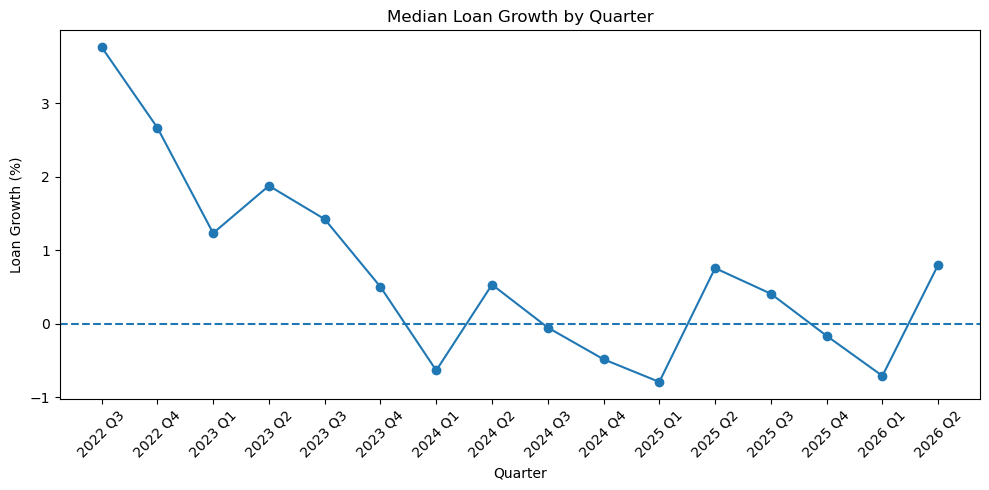

In [26]:
quarterly_growth["Quarter_Label"] = (
    quarterly_growth["Quarter"].dt.year.astype(str)
    + " Q"
    + quarterly_growth["Quarter"].dt.quarter.astype(str)
)

plt.figure(figsize=(10, 5))

plt.plot(
    quarterly_growth["Quarter_Label"],
    quarterly_growth["median"],
    marker="o"
)

plt.axhline(0, linestyle="--")

plt.title("Median Loan Growth by Quarter")
plt.xlabel("Quarter")
plt.ylabel("Loan Growth (%)")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Conclusion 1

We can conclude that loan growth weakened significantly after 2022. Median loan growth started above 3% in Q3 2022, but by 2024 through early 2026 it was often near or below 0%, showing that credit unions experienced much slower and less consistent loan growth later in the period.

In [27]:
# Calculate loan count growth

combined_df["Previous_Number_of_Loans"] = (
    combined_df
    .groupby("Credit_Union_Number")["Number_of_Loans"]
    .shift(1)
)

combined_df["Loan_Count_Growth"] = np.where(
    (combined_df["Consecutive_Quarter"]) &
    (combined_df["Previous_Number_of_Loans"] > 0),

    (
        (combined_df["Number_of_Loans"]
         - combined_df["Previous_Number_of_Loans"])
        / combined_df["Previous_Number_of_Loans"]
    ) * 100,

    np.nan
)

In [28]:
# Update analysis data

analysis_df = combined_df[
    combined_df["Members"] >= 100
].copy()

In [29]:
# Review loan count growth distribution

analysis_df["Loan_Count_Growth"].describe(
    percentiles=[.01, .05, .25, .50, .75, .95, .99]
)

count    72995.000000
mean         0.503675
std         28.835639
min       -100.000000
1%         -18.756918
5%          -7.262348
25%         -1.993963
50%         -0.082237
75%          1.619799
95%          7.195837
99%         26.888878
max       4394.376528
Name: Loan_Count_Growth, dtype: float64

In [30]:
# Set loan count growth outlier bounds

count_lower_bound = analysis_df["Loan_Count_Growth"].quantile(0.01)
count_upper_bound = analysis_df["Loan_Count_Growth"].quantile(0.99)

print("1st percentile:", count_lower_bound)
print("99th percentile:", count_upper_bound)

1st percentile: -18.75691788170003
99th percentile: 26.888877836964994


In [31]:
# Prepare data for correlation

loan_count_corr_df = analysis_df[
    analysis_df["Loan_Growth"].between(
        lower_bound,
        upper_bound
    )
    &
    analysis_df["Loan_Count_Growth"].between(
        count_lower_bound,
        count_upper_bound
    )
].copy()

loan_count_corr_df.shape

(70446, 24)

In [32]:
# Calculate correlation between loan growth and loan count growth

loan_count_correlation = loan_count_corr_df[
    ["Loan_Growth", "Loan_Count_Growth"]
].corr()

loan_count_correlation

,Loan_Growth,Loan_Count_Growth
Loan_Growth,1.000000,0.406328
Loan_Count_Growth,0.406328,1.000000


In [33]:
# Group loan count growth into categories

loan_count_corr_df["Loan_Count_Growth_Group"] = pd.qcut(
    loan_count_corr_df["Loan_Count_Growth"],
    q=5,
    labels=[
        "Lowest",
        "Low",
        "Middle",
        "High",
        "Highest"
    ]
)

loan_count_summary = (
    loan_count_corr_df
    .groupby("Loan_Count_Growth_Group", observed=True)["Loan_Growth"]
    .mean()
    .reset_index()
)

loan_count_summary

,Loan_Count_Growth_Group,Loan_Growth
0,Lowest,-1.580741
1,Low,-0.473224
2,Middle,0.598589
3,High,1.904176
4,Highest,3.709067


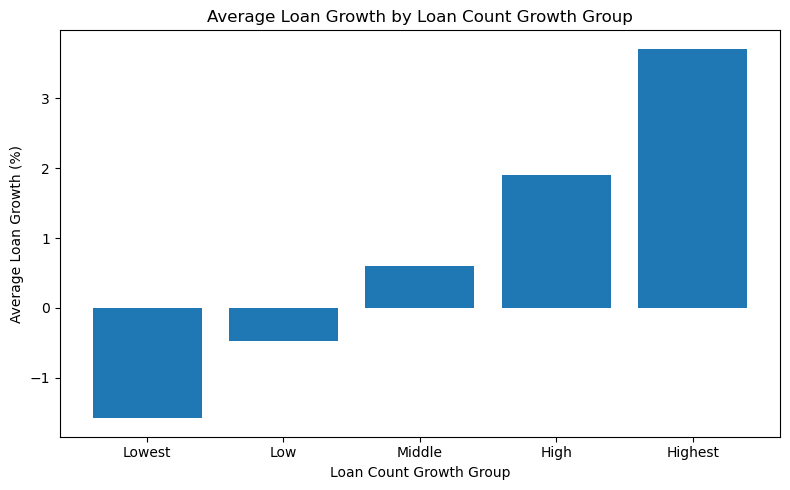

In [34]:
# Plot average loan growth by loan count growth group

plt.figure(figsize=(8, 5))

plt.bar(
    loan_count_summary["Loan_Count_Growth_Group"],
    loan_count_summary["Loan_Growth"]
)

plt.title("Average Loan Growth by Loan Count Growth Group")
plt.xlabel("Loan Count Growth Group")
plt.ylabel("Average Loan Growth (%)")

plt.tight_layout()
plt.show()

### Conclusion 2

We can conclude that there is a moderate positive relationship between loan count growth and total loan growth. As the number of loans increased, the average total loan growth also tended to increase.

In [35]:
# Prepare credit union level data for hypothesis testing

credit_union_summary = (
    growth_df
    .groupby("Credit_Union_Number")
    .agg(
        Average_Loan_Growth=("Loan_Growth", "mean"),
        Average_Total_Assets=("Total_Assets", "mean")
    )
    .dropna()
    .reset_index()
)

credit_union_summary.head()

,Credit_Union_Number,Average_Loan_Growth,Average_Total_Assets
0,1,0.407051,1.208812e+07
1,6,1.945538,2.685553e+08
2,12,1.926433,6.294750e+07
3,13,2.895597,1.099378e+09
4,16,0.178089,9.588157e+06


In [36]:
# Find median credit union asset size

median_assets = credit_union_summary["Average_Total_Assets"].median()

print("Median assets:", median_assets)

Median assets: 55652243.625


In [37]:
# Create small and large credit union groups

credit_union_summary["Size_Group"] = np.where(
    credit_union_summary["Average_Total_Assets"] >= median_assets,
    "Larger",
    "Smaller"
)

credit_union_summary["Size_Group"].value_counts()

Size_Group
Smaller    2462
Larger     2462
Name: count, dtype: int64

In [38]:
# Compare average loan growth by size group

size_group_summary = (
    credit_union_summary
    .groupby("Size_Group")["Average_Loan_Growth"]
    .agg(["mean", "median", "count"])
)

size_group_summary

,mean,median,count
Size_Group,,,
Larger,1.219856,1.202197,2462
Smaller,0.423629,0.423097,2462


In [39]:
# Create smaller and larger credit union samples

smaller_growth = credit_union_summary.loc[
    credit_union_summary["Size_Group"] == "Smaller",
    "Average_Loan_Growth"
]

larger_growth = credit_union_summary.loc[
    credit_union_summary["Size_Group"] == "Larger",
    "Average_Loan_Growth"
]

### Hypotheses

H0: Average loan growth is the same for larger and smaller credit unions.

H1: Average loan growth is different for larger and smaller credit unions.

In [40]:
# Perform Welch two-sample t-test

from scipy import stats

t_statistic, p_value = stats.ttest_ind(
    larger_growth,
    smaller_growth,
    equal_var=False
)

print("T-statistic:", t_statistic)
print("P-value:", p_value)

T-statistic: 14.482180111294161
P-value: 2.3730842632900856e-46


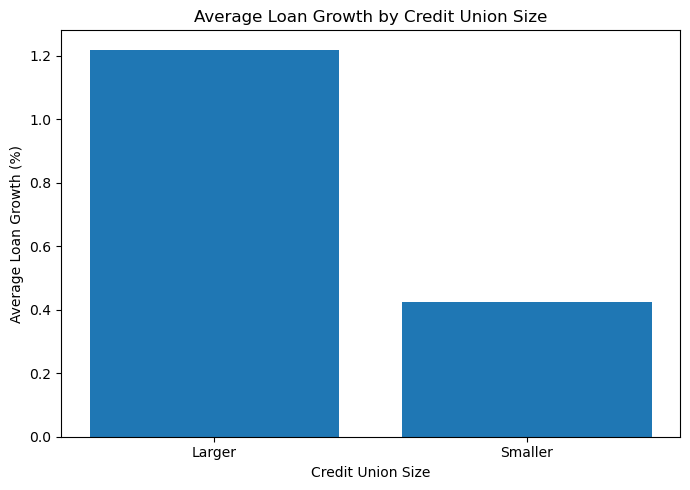

In [41]:
# Plot average loan growth by credit union size

size_plot = (
    credit_union_summary
    .groupby("Size_Group")["Average_Loan_Growth"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(7, 5))

plt.bar(
    size_plot["Size_Group"],
    size_plot["Average_Loan_Growth"]
)

plt.title("Average Loan Growth by Credit Union Size")
plt.xlabel("Credit Union Size")
plt.ylabel("Average Loan Growth (%)")

plt.tight_layout()
plt.show()

### Conclusion 3

We rejected the null hypothesis because the p-value was below 0.05. We can conclude that larger credit unions had higher average loan growth than smaller credit unions, and the difference between the two groups was statistically significant.